# qregime tutorial: QEM, QEC or FTQC?

Before running a quantum circuit you have to decide how to deal with errors:

* **QEM** (error *mitigation*): run it on the raw physical qubits and correct the statistics afterwards. Cheap in qubits, but it only works while the circuit is short enough that noise hasn't drowned the signal.
* **QEC / FTQC** (error *correction* / full fault tolerance): encode every logical qubit into many physical ones. Arbitrarily reliable, but the overhead is often thousands of physical qubits per circuit.
* **Partial QEC**: a small code that doesn't reach full fault tolerance but buys real reliability at a fraction of the cost.

`qregime` makes that decision explicit and reproducible from a single OpenQASM file. This tutorial walks through each step on real circuits, including the cases where the tool says **"no regime works yet"** and why that is a useful answer.

Runtime: about 2 minutes.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import qregime
print("qregime", qregime.__version__)

CIRCUITS = "../examples/circuits"
path = lambda name: f"{CIRCUITS}/{name}.qasm"

qregime 0.1.0


## 1. Hardware profiles

The only place hardware enters the tool is a small profile: the two-qubit error rate and the connectivity. Everything else (profiling, recommendations) is hardware-agnostic by construction. Three published profiles ship with the package; you can define your own with `qregime.HardwareProfile`.

In [2]:
for key, hw in qregime.HARDWARE_PROFILES.items():
    print(f"{key:28s} p_2q = {hw.p_2q:<7g} {hw.connectivity}")

superconductor_ibm           p_2q = 0.0032  limited
trapped_ion_quantinuum_h2    p_2q = 0.001   all_to_all
trapped_ion_ionq_oxford      p_2q = 0.0001  all_to_all


## 2. Profile a circuit

`profile()` reads the QASM and computes structural features: size, T-count (the expensive non-Clifford gates in fault-tolerant computing), how the qubits interact, how many qubits are really alive at the same time (a mid-circuit-measurement reuse opportunity), and how entangled the final state is.

In [3]:
p = qregime.profile(path("shor_like_sequential"))
for k in ("num_qubits", "num_gates", "tcount", "two_qubit_count",
          "max_concurrent_qubits", "qubit_reuse_potential_fraction",
          "zz_cost_operator_motif_fraction", "final_state_entanglement_fraction"):
    print(f"{k:34s} {p[k]}")

num_qubits                         16
num_gates                          28618
tcount                             3930
two_qubit_count                    3108
max_concurrent_qubits              11
qubit_reuse_potential_fraction     0.3125
zz_cost_operator_motif_fraction    0.0
final_state_entanglement_fraction  0.2916702543463684


Two things to notice: the circuit declares 16 qubits but only 11 are ever alive at the same time (31% reuse potential), and its T-count of 3,930 is what makes fault tolerance expensive for it.

## 3. Which reduction techniques are worth trying?

Reducing a circuit *before* choosing a regime can flip the decision. `recommend()` says which techniques are worth trying and why.

The most interesting case is ZX-calculus T-count reduction. The paper proves (Proposition 1) that when all the non-Clifford content of a circuit is a single layer of diagonal $Z_aZ_b$ rotations on distinct qubit pairs (the structure of a QAOA cost layer, or an Ising Trotter step), ZX-calculus **cannot** reduce the T-count at all. The feature `zz_cost_operator_motif_fraction` detects that structure. Let's check the prediction against the real reduction:

In [4]:
import pyzx as zx
from qregime.zx_reduction import zx_reduce
from qregime.hypergraph import resource_report

print(f"{'circuit':26s} {'motif':>6s} {'T before':>9s} {'T after':>8s} {'reduction':>10s}")
for name in ["adder8", "qft10", "qaoa_farm", "kicked_ising_analog_16q"]:
    circ = zx.Circuit.from_qasm_file(path(name)).to_basic_gates()
    before = resource_report(circ)["tcount"]
    after = resource_report(zx_reduce(circ))["tcount"]
    motif = qregime.profile(path(name))["zz_cost_operator_motif_fraction"]
    print(f"{name:26s} {motif:6.2f} {before:9d} {after:8d} {(before - after) / before:10.0%}")

circuit                     motif  T before  T after  reduction


adder8                       0.00       112       64        43%


qft10                        0.00       135       63        53%


qaoa_farm                    1.00        56       56         0%


kicked_ising_analog_16q      1.00       124      124         0%


Circuits with the diagonal-layer motif (`motif = 1.0`) get exactly 0% reduction, as the proposition says; the others get 43-53%. The tool uses this to warn you *before* you spend compile time:

In [5]:
for name in ["adder8", "qaoa_farm"]:
    recs = qregime.recommend(path(name))
    zxr = recs["zx_calculus_tcount_reduction"]
    print(f"{name:10s} -> recommended: {zxr['recommended']}")

adder8     -> recommended: True


qaoa_farm  -> recommended: WARNING


*(The `reason` strings are currently in Spanish, the language the research was done in. Translating them is an open, welcome contribution.)*

## 4. What would full fault tolerance cost?

`estimate_ftqc()` picks the surface-code distance from this project's own threshold fit (Stim + PyMatching simulation, not a number from a paper) and adds Litinski's 15-to-1 magic-state factories. The same circuit on three kinds of hardware:

In [6]:
p = qregime.profile(path("shor_like_sequential"))
for key, hw in qregime.HARDWARE_PROFILES.items():
    for label, n in (("declared qubits", p["num_qubits"]), ("with reuse", p["max_concurrent_qubits"])):
        r = qregime.estimate_ftqc(n, p["tcount"], hw.p_2q)
        print(f"{key:28s} {label:16s} d={r['codeDistance']:2d}  {r['physicalQubits']:>7,} physical qubits")

superconductor_ibm           declared qubits  d=23   29,654 physical qubits
superconductor_ibm           with reuse       d=23   24,024 physical qubits
trapped_ion_quantinuum_h2    declared qubits  d= 9    4,790 physical qubits
trapped_ion_quantinuum_h2    with reuse       d= 9    3,850 physical qubits
trapped_ion_ionq_oxford      declared qubits  d= 5    1,574 physical qubits
trapped_ion_ionq_oxford      with reuse       d= 5    1,254 physical qubits


Better hardware shrinks the code distance, and qubit reuse shrinks the number of logical patches. Both matter by thousands of physical qubits, which is why the tool reports both.

## 5. The budget question: what can I get with the qubits I actually have?

Full fault tolerance for this circuit on superconducting hardware needs ~30,000 physical qubits; the largest single device reported so far has 1,121. Instead of answering "not feasible", `best_within_budget()` returns the best reliability reachable at a fixed budget and its confidence quartile. The paper proves (Proposition 3) that this can only improve as the budget grows, so the curve below is guaranteed to be a staircase that never steps down.

In [7]:
for budget in (1_121, 5_000, 8_000, 10_000, 15_000):
    r = qregime.best_within_budget(16, 3930, 0.0032, budget)
    print(f"budget {budget:>6,}: d={r['code_distance']:2d}  reliability {r['reliability']:6.1%}  "
          f"(quartile {r['confidence_quartile']}, {r['confidence_label']})")

budget  1,121: d= 3  reliability   0.0%  (quartile 1, low)
budget  5,000: d= 9  reliability  12.6%  (quartile 1, low)
budget  8,000: d=11  reliability  40.8%  (quartile 2, low-moderate)
budget 10,000: d=13  reliability  67.8%  (quartile 3, moderate)
budget 15,000: d=15  reliability  84.5%  (quartile 4, high)


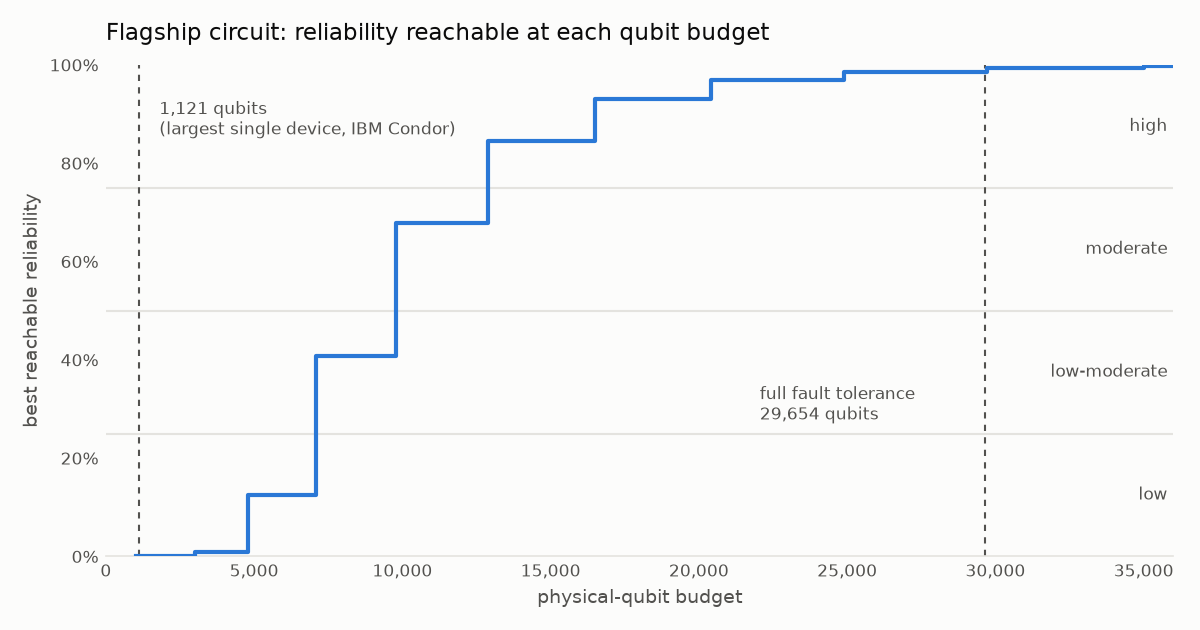

In [8]:
import sys
sys.path.insert(0, "../examples")
from budget_staircase import plot
from IPython.display import Image

Image(plot("budget_staircase.png"), width=720)

Reading the chart: at today's largest device (dashed line on the left) no code distance helps this circuit yet; reliability leaves the lowest quartile only around 5,000-8,000 qubits, and partial QEC at ~10,000 qubits already gives 68% reliability, one third of the cost of full fault tolerance. That is the kind of number a hardware roadmap needs.

## 6. The decision

`decide_regime()` puts it all together: the cheapest regime whose reliability meets your target within your budget, or an explicit, quantified gap if none does.

In [9]:
for name in ["vqe_ansatz", "adder8", "shor_like_sequential"]:
    r = qregime.decide_regime(path(name), hardware="superconductor_ibm",
                              physical_qubit_budget=1_121, reliability_target=0.5)
    print(f"{name:22s} regime={r['regime']:5s}  QEM reliability={r['qem']['reliability']:.1%}  "
          f"FTQC qubits={r['ftqc']['cost_qubits']:,}")
    if r["gap"]:
        g = r["gap"]
        print(f"{'':22s} gap: QEM short by {g['qem_reliability_shortfall']:.0%}, "
              f"FTQC over budget by {g['ftqc_qubit_overrun']:,} qubits")

vqe_ansatz             regime=QEM    QEM reliability=95.6%  FTQC qubits=6,726


adder8                 regime=QEM    QEM reliability=75.3%  FTQC qubits=13,842


shor_like_sequential   regime=GAP    QEM reliability=0.0%  FTQC qubits=29,654
                       gap: QEM short by 50%, FTQC over budget by 28,533 qubits


Changing the hardware changes the answer without touching the circuit. On a device with 99.99% two-qubit fidelity, the same circuit that had no viable regime above now runs acceptably *without any error correction*: better hardware doesn't only make fault tolerance cheaper, it can make it unnecessary for a given circuit.

In [10]:
for hw in qregime.HARDWARE_PROFILES:
    r = qregime.decide_regime(path("shor_like_sequential"), hardware=hw)
    print(f"{hw:28s} regime={r['regime']:5s}  QEM reliability={r['qem']['reliability']:5.1%}  "
          f"FTQC qubits={r['ftqc']['cost_qubits']:>6,}")

superconductor_ibm           regime=GAP    QEM reliability= 0.0%  FTQC qubits=29,654


trapped_ion_quantinuum_h2    regime=GAP    QEM reliability=10.0%  FTQC qubits= 4,790


trapped_ion_ionq_oxford      regime=QEM    QEM reliability=83.3%  FTQC qubits= 1,574


## 7. Where the QEM reliability number comes from (and when not to trust it)

For small circuits the QEM reliability comes from a noisy simulation: the fraction of shots that land on outputs the ideal circuit can produce. That metric is **useless** when the ideal circuit can produce almost every output (QAOA, VQE, QFT on superposed inputs): every noisy shot "succeeds". `qregime` detects this and falls back to an analytic proxy, and tells you so:

In [11]:
for name in ["adder8", "vqe_ansatz"]:
    r = qregime.decide_regime(path(name))
    print(f"{name:12s} {r['qem']['reliability']:.1%}  <- {r['qem']['reliability_source']}")

adder8       75.3%  <- noisy_simulation (150 shots)
vqe_ansatz   95.6%  <- analytic_proxy (1-p_2q)^two_qubit_count; noisy simulation not used: ideal output support covers 100% of all bitstrings, so it cannot detect errors


If you have a better number (measured on hardware, or from your own mitigation stack), pass it in with `qem_success_fraction=` and the decision uses it.

## 8. Honest limitations

These are stated in the paper and in the code, not hidden:

* **Partial QEC is an extrapolation.** Small code distances use a threshold model calibrated for full fault tolerance; it has not been separately validated at d = 3-11.
* **No predictor of "will ZX-calculus help?" beats the majority baseline on unseen circuit families** (three attempts, including logistic regression and decision trees under leave-one-family-out validation). Proposition 1 gives an exact answer only for the diagonal-layer case.
* **Dynamic circuits** (mid-circuit measurement with classically controlled corrections) cannot be ingested yet: neither this tool nor the ZX-calculus state of the art we tested can represent arbitrary-angle classically-controlled corrections.
* **The QEM noise model** is generic two-qubit depolarizing noise; no readout, T1/T2 or crosstalk.
* **Speed:** pyzx's QASM parser becomes the bottleneck for circuits with many distinct rotation angles (a 24-qubit QFT did not finish in minutes).

Contributions on any of these are very welcome; see `CONTRIBUTING.md`.